Analisis Eksploratif dan Evaluasi Model Machine Learning untuk Prediksi Kualitas dan Klasifikasi Jenis Wine Berdasarkan Karakteristik Fisikokimia
# 01 — Data Preparation: Wine Quality Dataset

## 1. Deskripsi

Notebook ini digunakan untuk melakukan tahap *data preparation* pada dataset Wine Quality yang terdiri dari data red wine dan white wine. Tahapan ini bertujuan untuk memahami struktur data, memeriksa kualitas data, menggabungkan kedua dataset, serta melakukan pembersihan data sebelum digunakan dalam analisis dan pemodelan Machine Learning.

## 2. Tujuan

Tujuan dari tahap data preparation ini adalah:

1. Memuat dan memahami struktur dataset red wine dan white wine.
2. Memeriksa tipe data, missing values, duplikat, serta potensi nilai yang tidak valid.
3. Menggabungkan kedua dataset dan menambahkan variabel `wine_type` sebagai label jenis wine.
4. Menganalisis distribusi awal variabel `quality` dan `wine_type`.
5. Mengevaluasi dampak penghapusan duplikat terhadap jumlah dan distribusi data.
6. Melakukan validasi serta menyimpan dataset hasil cleaning.

## 3. Dataset

Dataset yang digunakan terdiri dari dua sumber:

- `winequality-red.csv`: data karakteristik kimia red wine.
- `winequality-white.csv`: data karakteristik kimia white wine.

Kedua dataset memiliki variabel karakteristik kimia yang sama dan variabel target `quality`. Setelah digabungkan, ditambahkan variabel `wine_type` dengan ketentuan:

| Nilai | Jenis wine |
|---:|---|
| 0 | Red wine |
| 1 | White wine |

Dataset gabungan memiliki 13 kolom, yang terdiri dari 11 variabel karakteristik kimia, 1 variabel `quality`, dan 1 variabel `wine_type`.

## 4. Tahapan Pengerjaan

Tahapan yang dilakukan dalam notebook ini meliputi:

1. **Data Loading** — memuat dataset dari file CSV.
2. **Initial Data Inspection** — memeriksa struktur, tipe data, dan kualitas awal dataset.
3. **Data Integration** — menggabungkan dataset red wine dan white wine.
4. **Data Quality Audit** — memeriksa missing values, duplikat, nilai tak hingga, dan distribusi variabel.
5. **Data Cleaning** — mengevaluasi dan menangani duplikat berdasarkan hasil audit.
6. **Data Validation** — memeriksa kembali dataset setelah cleaning.
7. **Data Export** — menyimpan dataset hasil cleaning untuk digunakan pada tahap berikutnya.

## 5. Output

Output dari notebook ini adalah dataset hasil cleaning yang disimpan dalam format CSV pada lokasi:

`data/processed/winequality_cleaned.csv`

Dataset tersebut akan digunakan sebagai masukan untuk tahap *Exploratory Data Analysis* (EDA) dan eksperimen Machine Learning berikutnya.

## 6. Catatan

Penghapusan duplikat dilakukan setelah mengevaluasi kondisi dan dampaknya terhadap distribusi data. Dataset asli tetap dipertahankan sebagai sumber agar proses preprocessing dapat ditinjau dan direproduksi kembali.

In [2]:
# Import library untuk audit dataset

from pathlib import Path

import pandas as pd
import numpy as np

# Pengaturan tampilan pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 4)

print("Library berhasil diimpor.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Library berhasil diimpor.
Pandas version: 3.0.5
NumPy version: 2.5.2


In [3]:
# Menentukan direktori proyek secara otomatis

PROJECT_ROOT = Path.cwd()

# Jika notebook dijalankan dari folder notebooks,
# direktori proyek berada satu tingkat di atasnya.
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

RED_PATH = DATA_DIR / "winequality-red.csv"
WHITE_PATH = DATA_DIR / "winequality-white.csv"

print("Direktori proyek :", PROJECT_ROOT)
print("Direktori data   :", DATA_DIR)
print("File red wine   :", RED_PATH.exists())
print("File white wine :", WHITE_PATH.exists())

Direktori proyek : d:\MachineLearning\Wine
Direktori data   : d:\MachineLearning\Wine\data
File red wine   : True
File white wine : True


In [4]:
# Membaca dataset sumber

df_red_raw = pd.read_csv(RED_PATH, sep=";")
df_white_raw = pd.read_csv(WHITE_PATH, sep=";")

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


In [5]:
# Melihat lima baris pertama dari masing-masing dataset

print("RED WINE")
display(df_red_raw.head())

print("WHITE WINE")
display(df_white_raw.head())

RED WINE


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


WHITE WINE


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [6]:
# Audit ukuran dan struktur dataset

print("RED WINE")
print("Shape:", df_red_raw.shape)
print("Columns:", df_red_raw.columns.tolist())

print("\nWHITE WINE")
print("Shape:", df_white_raw.shape)
print("Columns:", df_white_raw.columns.tolist())

print("\nAUDIT STRUKTUR")
print(
    "Nama dan urutan kolom sama:",
    df_red_raw.columns.equals(df_white_raw.columns)
)

print(
    "Kolom khusus red wine:",
    sorted(set(df_red_raw.columns) - set(df_white_raw.columns))
)

print(
    "Kolom khusus white wine:",
    sorted(set(df_white_raw.columns) - set(df_red_raw.columns))
)

print(
    "\nTotal baris sebelum penggabungan:",
    len(df_red_raw) + len(df_white_raw)
)

RED WINE
Shape: (1599, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

WHITE WINE
Shape: (4898, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

AUDIT STRUKTUR
Nama dan urutan kolom sama: True
Kolom khusus red wine: []
Kolom khusus white wine: []

Total baris sebelum penggabungan: 6497


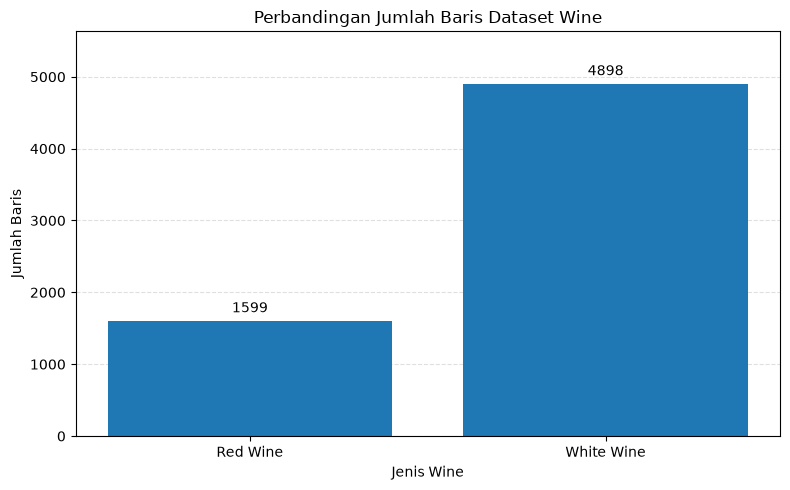

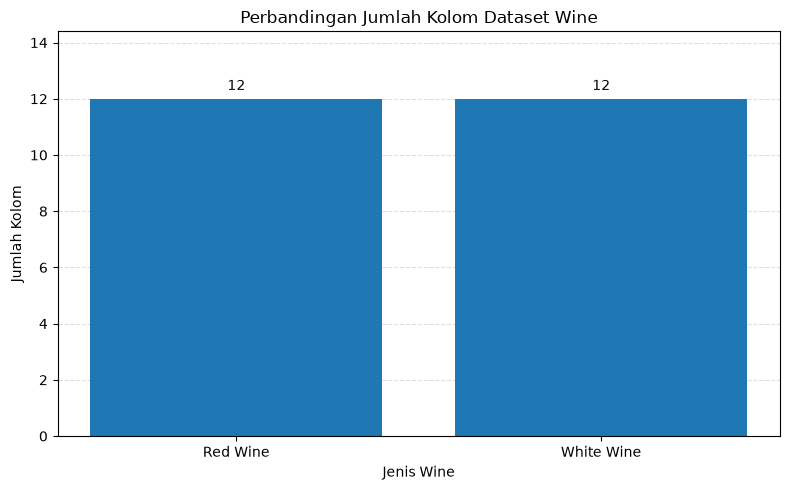

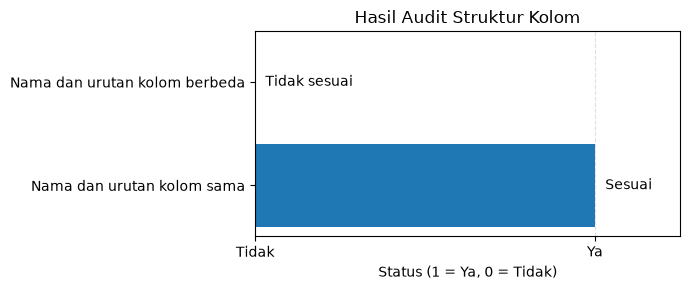

,Jenis Wine,Jumlah Baris,Jumlah Kolom
0,Red Wine,1599,12
1,White Wine,4898,12


Total baris sebelum penggabungan: 6497
Struktur kolom identik: Ya


In [7]:

import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# 1. Menyiapkan data hasil audit
# ==========================================

dataset_names = ["Red Wine", "White Wine"]

row_counts = [
    len(df_red_raw),
    len(df_white_raw)
]

column_counts = [
    len(df_red_raw.columns),
    len(df_white_raw.columns)
]

same_columns = df_red_raw.columns.equals(df_white_raw.columns)

total_rows = sum(row_counts)
total_columns = len(df_red_raw.columns)

# ==========================================
# 2. Visualisasi jumlah baris dataset
# ==========================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(dataset_names, row_counts)

ax.set_title("Perbandingan Jumlah Baris Dataset Wine")
ax.set_xlabel("Jenis Wine")
ax.set_ylabel("Jumlah Baris")
ax.bar_label(bars, fmt="%.0f", padding=4)

ax.set_ylim(0, max(row_counts) * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# ==========================================
# 3. Visualisasi jumlah kolom dataset
# ==========================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(dataset_names, column_counts)

ax.set_title("Perbandingan Jumlah Kolom Dataset Wine")
ax.set_xlabel("Jenis Wine")
ax.set_ylabel("Jumlah Kolom")
ax.bar_label(bars, fmt="%.0f", padding=4)

ax.set_ylim(0, max(column_counts) * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# ==========================================
# 4. Visualisasi kesamaan struktur kolom
# ==========================================

fig, ax = plt.subplots(figsize=(7, 3))

status_labels = [
    "Nama dan urutan kolom sama",
    "Nama dan urutan kolom berbeda"
]

status_values = [
    int(same_columns),
    int(not same_columns)
]

bars = ax.barh(
    status_labels,
    status_values
)

ax.set_title("Hasil Audit Struktur Kolom")
ax.set_xlabel("Status (1 = Ya, 0 = Tidak)")
ax.set_xlim(0, 1.25)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Tidak", "Ya"])

for bar, value in zip(bars, status_values):
    label = "Sesuai" if value == 1 else "Tidak sesuai"
    ax.text(
        value + 0.03,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center"
    )

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# ==========================================
# 5. Ringkasan hasil audit
# ==========================================

audit_summary = pd.DataFrame({
    "Jenis Wine": dataset_names,
    "Jumlah Baris": row_counts,
    "Jumlah Kolom": column_counts
})

display(audit_summary)

print("Total baris sebelum penggabungan:", total_rows)
print("Struktur kolom identik:", "Ya" if same_columns else "Tidak")


In [8]:
# Audit struktur dataset red dan white wine

print("=" * 50)
print("STRUKTUR RED WINE")
print("=" * 50)
df_red_raw.info()

print("\n" + "=" * 50)
print("STRUKTUR WHITE WINE")
print("=" * 50)
df_white_raw.info()

STRUKTUR RED WINE
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

STRUKTUR WHITE WINE
<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #

In [9]:
# Ringkasan tipe data kedua dataset

audit_dtypes = pd.DataFrame({
    "red_dtype": df_red_raw.dtypes.astype(str),
    "white_dtype": df_white_raw.dtypes.astype(str),
})

audit_dtypes["same_dtype"] = (
    audit_dtypes["red_dtype"] == audit_dtypes["white_dtype"]
)

display(audit_dtypes)

,red_dtype,white_dtype,same_dtype
fixed acidity,float64,float64,True
volatile acidity,float64,float64,True
citric acid,float64,float64,True
residual sugar,float64,float64,True
chlorides,float64,float64,True
free sulfur dioxide,float64,float64,True
total sulfur dioxide,float64,float64,True
density,float64,float64,True
pH,float64,float64,True
sulphates,float64,float64,True


In [10]:
# Audit missing values

missing_audit = pd.DataFrame({
    "red_missing": df_red_raw.isna().sum(),
    "white_missing": df_white_raw.isna().sum(),
})

missing_audit["red_missing_pct"] = (
    missing_audit["red_missing"]
    / len(df_red_raw) * 100
)

missing_audit["white_missing_pct"] = (
    missing_audit["white_missing"]
    / len(df_white_raw) * 100
)

display(missing_audit)

print(
    "\nTotal missing values red wine:",
    int(df_red_raw.isna().sum().sum())
)

print(
    "Total missing values white wine:",
    int(df_white_raw.isna().sum().sum())
)

,red_missing,white_missing,red_missing_pct,white_missing_pct
fixed acidity,0,0,0.0,0.0
volatile acidity,0,0,0.0,0.0
citric acid,0,0,0.0,0.0
residual sugar,0,0,0.0,0.0
chlorides,0,0,0.0,0.0
free sulfur dioxide,0,0,0.0,0.0
total sulfur dioxide,0,0,0.0,0.0
density,0,0,0.0,0.0
pH,0,0,0.0,0.0
sulphates,0,0,0.0,0.0



Total missing values red wine: 0
Total missing values white wine: 0


In [11]:
# Menghitung duplikat pada setiap dataset sumber

duplicate_red = df_red_raw.duplicated().sum()
duplicate_white = df_white_raw.duplicated().sum()

duplicate_audit_raw = pd.DataFrame({
    "dataset": ["Red wine", "White wine"],
    "total_rows": [len(df_red_raw), len(df_white_raw)],
    "duplicate_rows": [duplicate_red, duplicate_white],
})

duplicate_audit_raw["duplicate_pct"] = (
    duplicate_audit_raw["duplicate_rows"]
    / duplicate_audit_raw["total_rows"]
    * 100
)

display(duplicate_audit_raw)

,dataset,total_rows,duplicate_rows,duplicate_pct
0,Red wine,1599,240,15.0094
1,White wine,4898,937,19.1303


In [12]:
# Melihat semua baris yang termasuk dalam kelompok duplikat

red_duplicates = df_red_raw[
    df_red_raw.duplicated(keep=False)
].sort_values(by=df_red_raw.columns.tolist())

white_duplicates = df_white_raw[
    df_white_raw.duplicated(keep=False)
].sort_values(by=df_white_raw.columns.tolist())

print("Jumlah baris dalam kelompok duplikat red wine:",
      len(red_duplicates))

print("Jumlah baris dalam kelompok duplikat white wine:",
      len(white_duplicates))

Jumlah baris dalam kelompok duplikat red wine: 460
Jumlah baris dalam kelompok duplikat white wine: 1709


In [13]:
# Membuat salinan agar data sumber tetap tidak berubah

df_red_audit = df_red_raw.copy()
df_white_audit = df_white_raw.copy()

# Menambahkan label jenis wine
df_red_audit["wine_type"] = 0
df_white_audit["wine_type"] = 1

# Menggabungkan kedua dataset
df_combined = pd.concat(
    [df_red_audit, df_white_audit],
    ignore_index=True
)

print("Ukuran red wine   :", df_red_audit.shape)
print("Ukuran white wine :", df_white_audit.shape)
print("Ukuran gabungan   :", df_combined.shape)

display(df_combined.head())

Ukuran red wine   : (1599, 13)
Ukuran white wine : (4898, 13)
Ukuran gabungan   : (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [14]:
# Memastikan distribusi label wine_type

wine_type_counts = (
    df_combined["wine_type"]
    .value_counts()
    .rename(index={
        0: "Red wine",
        1: "White wine"
    })
)

wine_type_summary = pd.DataFrame({
    "count": wine_type_counts,
    "percentage": wine_type_counts / len(df_combined) * 100
})

display(wine_type_summary)

,count,percentage
wine_type,,
White wine,4898,75.3886
Red wine,1599,24.6114


In [15]:
# Audit duplikat pada dataset gabungan

# Duplikat identik pada seluruh kolom, termasuk wine_type
duplicate_all_columns = int(
    df_combined.duplicated().sum()
)

# Duplikat berdasarkan fitur dan quality,
# tanpa mempertimbangkan wine_type
feature_cols = [
    col for col in df_combined.columns
    if col != "wine_type"
]

duplicate_without_wine_type = int(
    df_combined.duplicated(
        subset=feature_cols
    ).sum()
)

print("AUDIT DUPLIKAT DATASET GABUNGAN")
print("=" * 50)

print(
    "Duplikat seluruh kolom:",
    duplicate_all_columns
)

print(
    "Duplikat fitur dan quality tanpa wine_type:",
    duplicate_without_wine_type
)

AUDIT DUPLIKAT DATASET GABUNGAN
Duplikat seluruh kolom: 1177
Duplikat fitur dan quality tanpa wine_type: 1179


In [16]:
# Mengidentifikasi kelompok fitur dan quality
# yang muncul pada lebih dari satu jenis wine

cross_type_groups = (
    df_combined
    .groupby(feature_cols)["wine_type"]
    .nunique()
)

cross_type_groups = cross_type_groups[
    cross_type_groups > 1
]

print(
    "Jumlah kelompok dengan wine_type berbeda:",
    len(cross_type_groups)
)

display(cross_type_groups)

Jumlah kelompok dengan wine_type berbeda: 2


fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density  pH    sulphates  alcohol  quality
5.9            0.19              0.21         1.7             0.045      57.0                 135.0                 0.9934   3.32  0.44       9.5      5          2
6.7            0.28              0.28         2.4             0.012      36.0                 100.0                 0.9906   3.26  0.39       11.7     7          2
Name: wine_type, dtype: int64

In [17]:
# Statistik deskriptif dataset gabungan dan masing-masing jenis wine

print("=" * 60)
print("STATISTIK DESKRIPTIF DATASET GABUNGAN")
print("=" * 60)
display(df_combined.describe().T)

print("\n" + "=" * 60)
print("STATISTIK DESKRIPTIF RED WINE")
print("=" * 60)
display(df_red_raw.describe().T)

print("\n" + "=" * 60)
print("STATISTIK DESKRIPTIF WHITE WINE")
print("=" * 60)
display(df_white_raw.describe().T)

STATISTIK DESKRIPTIF DATASET GABUNGAN


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.2153,1.2964,3.8000,6.4000,7.0000,7.700,15.900
volatile acidity,6497.0,0.3397,0.1646,0.0800,0.2300,0.2900,0.400,1.580
citric acid,6497.0,0.3186,0.1453,0.0000,0.2500,0.3100,0.390,1.660
residual sugar,6497.0,5.4432,4.7578,0.6000,1.8000,3.0000,8.100,65.800
chlorides,6497.0,0.0560,0.0350,0.0090,0.0380,0.0470,0.065,0.611
free sulfur dioxide,6497.0,30.5253,17.7494,1.0000,17.0000,29.0000,41.000,289.000
total sulfur dioxide,6497.0,115.7446,56.5219,6.0000,77.0000,118.0000,156.000,440.000
density,6497.0,0.9947,0.0030,0.9871,0.9923,0.9949,0.997,1.039
pH,6497.0,3.2185,0.1608,2.7200,3.1100,3.2100,3.320,4.010
sulphates,6497.0,0.5313,0.1488,0.2200,0.4300,0.5100,0.600,2.000



STATISTIK DESKRIPTIF RED WINE


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.3196,1.7411,4.6000,7.1000,7.9000,9.2000,15.9000
volatile acidity,1599.0,0.5278,0.1791,0.1200,0.3900,0.5200,0.6400,1.5800
citric acid,1599.0,0.2710,0.1948,0.0000,0.0900,0.2600,0.4200,1.0000
residual sugar,1599.0,2.5388,1.4099,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1599.0,0.0875,0.0471,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1599.0,15.8749,10.4602,1.0000,7.0000,14.0000,21.0000,72.0000
total sulfur dioxide,1599.0,46.4678,32.8953,6.0000,22.0000,38.0000,62.0000,289.0000
density,1599.0,0.9967,0.0019,0.9901,0.9956,0.9968,0.9978,1.0037
pH,1599.0,3.3111,0.1544,2.7400,3.2100,3.3100,3.4000,4.0100
sulphates,1599.0,0.6581,0.1695,0.3300,0.5500,0.6200,0.7300,2.0000



STATISTIK DESKRIPTIF WHITE WINE


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.8548,0.8439,3.8000,6.3000,6.8000,7.3000,14.200
volatile acidity,4898.0,0.2782,0.1008,0.0800,0.2100,0.2600,0.3200,1.100
citric acid,4898.0,0.3342,0.1210,0.0000,0.2700,0.3200,0.3900,1.660
residual sugar,4898.0,6.3914,5.0721,0.6000,1.7000,5.2000,9.9000,65.800
chlorides,4898.0,0.0458,0.0218,0.0090,0.0360,0.0430,0.0500,0.346
free sulfur dioxide,4898.0,35.3081,17.0071,2.0000,23.0000,34.0000,46.0000,289.000
total sulfur dioxide,4898.0,138.3607,42.4981,9.0000,108.0000,134.0000,167.0000,440.000
density,4898.0,0.9940,0.0030,0.9871,0.9917,0.9937,0.9961,1.039
pH,4898.0,3.1883,0.1510,2.7200,3.0900,3.1800,3.2800,3.820
sulphates,4898.0,0.4898,0.1141,0.2200,0.4100,0.4700,0.5500,1.080


In [18]:
# Memeriksa nilai non-finite pada kolom numerik

numeric_cols = df_combined.select_dtypes(
    include=np.number
).columns

non_finite_audit = pd.DataFrame({
    "positive_infinity": np.isposinf(
        df_combined[numeric_cols]
    ).sum(),
    "negative_infinity": np.isneginf(
        df_combined[numeric_cols]
    ).sum(),
})

display(non_finite_audit)

,positive_infinity,negative_infinity
fixed acidity,0,0
volatile acidity,0,0
citric acid,0,0
residual sugar,0,0
chlorides,0,0
free sulfur dioxide,0,0
total sulfur dioxide,0,0
density,0,0
pH,0,0
sulphates,0,0


In [19]:
# Analisis distribusi quality

# 1. Memeriksa nilai unik dan rentang quality
print("Nilai quality yang ditemukan:")
print(sorted(df_combined["quality"].dropna().unique()))

print("\nNilai minimum quality:",
      df_combined["quality"].min())

print("Nilai maksimum quality:",
      df_combined["quality"].max())


# 2. Menghitung frekuensi dan persentase quality
quality_counts = (
    df_combined["quality"]
    .value_counts()
    .sort_index()
)

quality_summary = pd.DataFrame({
    "count": quality_counts,
    "percentage": quality_counts / len(df_combined) * 100
})

print("\nDistribusi quality keseluruhan:")
display(quality_summary)


# 3. Membandingkan quality berdasarkan jenis wine
quality_by_type = pd.crosstab(
    df_combined["quality"],
    df_combined["wine_type"],
    margins=True
)

quality_by_type = quality_by_type.rename(
    columns={
        0: "Red wine",
        1: "White wine"
    }
)

print("\nDistribusi quality berdasarkan jenis wine:")
display(quality_by_type)

Nilai quality yang ditemukan:
[np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Nilai minimum quality: 3
Nilai maksimum quality: 9

Distribusi quality keseluruhan:


,count,percentage
quality,,
3,30,0.4618
4,216,3.3246
5,2138,32.9075
6,2836,43.6509
7,1079,16.6077
8,193,2.9706
9,5,0.0770



Distribusi quality berdasarkan jenis wine:


wine_type,Red wine,White wine,All
quality,,,
3,10,20,30
4,53,163,216
5,681,1457,2138
6,638,2198,2836
7,199,880,1079
8,18,175,193
9,0,5,5
All,1599,4898,6497


In [20]:

# Ringkasan kondisi dataset sebelum cleaning

audit_summary = pd.DataFrame({
    "metric": [
        "Jumlah baris red wine",
        "Jumlah baris white wine",
        "Total baris gabungan",
        "Jumlah kolom gabungan",
        "Missing values gabungan",
        "Duplikat semua kolom",
        "Duplikat tanpa wine_type",
        "Kelompok lintas jenis wine",
    ],
    "value": [
        len(df_red_raw),
        len(df_white_raw),
        len(df_combined),
        len(df_combined.columns),
        int(df_combined.isna().sum().sum()),
        int(df_combined.duplicated().sum()),
        int(df_combined.duplicated(subset=feature_cols).sum()),
        len(cross_type_groups),
    ]
})

display(audit_summary)


,metric,value
0,Jumlah baris red wine,1599
1,Jumlah baris white wine,4898
2,Total baris gabungan,6497
3,Jumlah kolom gabungan,13
4,Missing values gabungan,0
5,Duplikat semua kolom,1177
6,Duplikat tanpa wine_type,1179
7,Kelompok lintas jenis wine,2


In [21]:

# Evaluasi duplikat sebelum cleaning

total_rows = len(df_combined)
duplicate_rows = int(df_combined.duplicated().sum())
duplicate_percentage = (
    duplicate_rows / total_rows * 100
    if total_rows > 0 else 0
)

print("Total baris sebelum cleaning:", total_rows)
print("Jumlah baris duplikat:", duplicate_rows)
print(f"Persentase duplikat: {duplicate_percentage:.2f}%")

# Membandingkan jumlah baris setelah duplikat persis dihapus
df_no_exact_duplicates = df_combined.drop_duplicates()

print(
    "Jumlah baris setelah simulasi penghapusan duplikat:",
    len(df_no_exact_duplicates)
)
print(
    "Jumlah baris yang berkurang:",
    total_rows - len(df_no_exact_duplicates)
)


Total baris sebelum cleaning: 6497
Jumlah baris duplikat: 1177
Persentase duplikat: 18.12%
Jumlah baris setelah simulasi penghapusan duplikat: 5320
Jumlah baris yang berkurang: 1177


In [22]:

# Evaluasi duplikat lintas jenis wine

# 1. Menghitung kelompok karakteristik yang muncul
#    pada kedua jenis wine
print(
    "Jumlah kelompok lintas jenis wine:",
    len(cross_type_groups)
)

# 2. Menghitung jumlah kelompok berdasarkan kombinasi
#    seluruh fitur selain wine_type
cross_type_counts = (
    df_combined
    .groupby(feature_cols, dropna=False)["wine_type"]
    .agg(["count", "nunique"])
)

# Mengambil kelompok yang memiliki lebih dari satu label wine_type
cross_type_conflicts = cross_type_counts[
    cross_type_counts["nunique"] > 1
]

print(
    "Jumlah kelompok dengan label wine_type berbeda:",
    len(cross_type_conflicts)
)

# 3. Menampilkan contoh baris yang termasuk kelompok tersebut
if not cross_type_conflicts.empty:
    cross_type_examples = (
        df_combined
        .set_index(feature_cols)
        .loc[cross_type_conflicts.index]
        .reset_index()
    )

    display(cross_type_examples.head(10))
else:
    print("Tidak ditemukan kelompok lintas jenis wine.")


Jumlah kelompok lintas jenis wine: 2
Jumlah kelompok dengan label wine_type berbeda: 2


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,5.9,0.19,0.21,1.7,0.045,57.0,135.0,0.9934,3.32,0.44,9.5,5,0
1,5.9,0.19,0.21,1.7,0.045,57.0,135.0,0.9934,3.32,0.44,9.5,5,1
2,6.7,0.28,0.28,2.4,0.012,36.0,100.0,0.9906,3.26,0.39,11.7,7,0
3,6.7,0.28,0.28,2.4,0.012,36.0,100.0,0.9906,3.26,0.39,11.7,7,0
4,6.7,0.28,0.28,2.4,0.012,36.0,100.0,0.9906,3.26,0.39,11.7,7,1


In [23]:

# Evaluasi dampak penghapusan duplikat persis

df_no_exact_duplicates = df_combined.drop_duplicates().copy()

print("Jumlah data sebelum cleaning:", len(df_combined))
print("Jumlah data setelah simulasi:", len(df_no_exact_duplicates))
print("Jumlah baris yang dihapus:",
      len(df_combined) - len(df_no_exact_duplicates))

# Membandingkan distribusi wine_type
print("\nDistribusi wine_type sebelum cleaning:")
display(df_combined["wine_type"].value_counts().sort_index())

print("\nDistribusi wine_type setelah simulasi:")
display(
    df_no_exact_duplicates["wine_type"]
    .value_counts()
    .sort_index()
)

# Membandingkan distribusi quality
quality_comparison = pd.concat(
    [
        df_combined["quality"].value_counts().sort_index().rename("before"),
        df_no_exact_duplicates["quality"].value_counts().sort_index().rename("after"),
    ],
    axis=1
).fillna(0).astype(int)

print("\nDistribusi quality sebelum dan setelah simulasi:")
display(quality_comparison)


Jumlah data sebelum cleaning: 6497
Jumlah data setelah simulasi: 5320
Jumlah baris yang dihapus: 1177

Distribusi wine_type sebelum cleaning:


wine_type
0    1599
1    4898
Name: count, dtype: int64


Distribusi wine_type setelah simulasi:


wine_type
0    1359
1    3961
Name: count, dtype: int64


Distribusi quality sebelum dan setelah simulasi:


,before,after
quality,,
3,30,30
4,216,206
5,2138,1752
6,2836,2323
7,1079,856
8,193,148
9,5,5


In [24]:

# Cleaning: menghapus duplikat persis

df_clean = df_combined.drop_duplicates().copy()

# Memastikan hasil cleaning sesuai dengan simulasi
assert len(df_clean) == 5320
assert df_clean.duplicated().sum() == 0

# Memeriksa missing values
print("Missing values setelah cleaning:")
print(df_clean.isna().sum().sum())

# Memeriksa duplikat tersisa
print("\nDuplikat persis setelah cleaning:")
print(df_clean.duplicated().sum())

# Memeriksa distribusi jenis wine
print("\nDistribusi wine_type setelah cleaning:")
display(df_clean["wine_type"].value_counts().sort_index())

print("\nUkuran dataset hasil cleaning:", df_clean.shape)


Missing values setelah cleaning:
0

Duplikat persis setelah cleaning:
0

Distribusi wine_type setelah cleaning:


wine_type
0    1359
1    3961
Name: count, dtype: int64


Ukuran dataset hasil cleaning: (5320, 13)


In [25]:

# Menyimpan dataset hasil cleaning

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_DATA_PATH = PROCESSED_DIR / "winequality_cleaned.csv"

df_clean.to_csv(CLEAN_DATA_PATH, index=False)

print("Dataset berhasil disimpan.")
print("Lokasi:", CLEAN_DATA_PATH)
print("Ukuran dataset:", df_clean.shape)


Dataset berhasil disimpan.
Lokasi: d:\MachineLearning\Wine\data\processed\winequality_cleaned.csv
Ukuran dataset: (5320, 13)


## Kesimpulan Data Preparation

Pada tahap data preparation, dataset red wine dan white wine digabungkan menjadi satu dataset dengan penambahan variabel `wine_type` sebagai label jenis wine. Red wine diberi label `0`, sedangkan white wine diberi label `1`.

Dataset awal terdiri dari 6.497 baris dan 13 kolom. Berdasarkan hasil audit, ditemukan 1.177 baris duplikat persis atau sekitar 18,12% dari total data. Setelah dilakukan penghapusan duplikat persis, jumlah data menjadi 5.320 baris.

Hasil validasi menunjukkan bahwa dataset hasil cleaning tidak memiliki missing values maupun duplikat persis. Dataset kemudian disimpan dalam format CSV dengan nama `winequality_cleaned.csv` pada folder `data/processed/`.

Dataset ini selanjutnya akan digunakan untuk analisis eksplorasi data (*Exploratory Data Analysis* atau EDA) dan eksperimen Machine Learning. Penghapusan duplikat merupakan keputusan preprocessing yang perlu diperhatikan dalam interpretasi hasil model karena dapat mengubah frekuensi pengamatan pada setiap kelas.